<h2>Machine Learning Assignment 2</h2>
<h3>Name: Ruthvik S</h3>
<h3>BITS ID: 2026aj05954</h3>

In [197]:
# Installing libraries if required

In [198]:
# %pip install numpy pandas matplotlib seaborn scikit-learn joblib streamlit

<h3>Importing all the necessary libraries</h3>

In [200]:
# Importing all necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, matthews_corrcoef


In [201]:
warnings.filterwarnings('ignore')

<h3>Loading Dataset, Exploring The Dataset, Performing Data Pre-processing</h3>

In [203]:
# Reading the dataset
dataset = pd.read_csv('breast_cancer.csv')

# Performing high level EDA on the dataset
print("Dataset dimensions: ", dataset.shape)
print('Dataset feature information: ')
dataset.info()

print("\nMissing values:", dataset.isnull().sum().sum() )
print("\nTarget distribution:", dataset['diagnosis'].value_counts() )

Dataset dimensions:  (569, 32)
Dataset feature information: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se         

In [204]:
# Removing unnecessary columns such as Id as they serve no purpose
dataset = dataset.drop( columns = ['id'] )

In [205]:
# Separate features and target
X = dataset.drop( columns = ['diagnosis'] )
y = dataset['diagnosis']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.20, random_state = 42, stratify = y)

# Converting the target column into numerical value
target_mapping = {'M': 1, 'B': 0}
y_train = y_train.map(target_mapping)
y_test = y_test.map(target_mapping)


In [206]:
# Scaling the features into a common scale so that the value changes over a single column do not impact the output
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


<h3>Training The Dataset Over 5 Different Models (Logistic Regression, Support Vector Machines, Decision Trees, K Nearest Neighbours and Gaussian Naive Bayes) and Evaluating Performance Over Metrics</h3>

In [208]:
# Logistic regression, training the dataset and metrics evalution

lr_model = LogisticRegression(max_iter = 1000, random_state = 42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[ : , 1]

lr_metrics = {
    'Accuracy' : accuracy_score(y_test, y_pred_lr)
    , 'AUC' : roc_auc_score(y_test, y_prob_lr)
    , 'Precision' : precision_score(y_test, y_pred_lr, pos_label = 1)
    , 'Recall' : recall_score(y_test, y_pred_lr, pos_label = 1)
    , 'F1 Score': f1_score(y_test, y_pred_lr, pos_label = 1)
    , 'MCC': matthews_corrcoef(y_test, y_pred_lr)
}

print("Logistic Regression Results:\n")
for metric, value in lr_metrics.items():
    print(f"{ metric } : { value }")

Logistic Regression Results:

Accuracy : 0.9649122807017544
AUC : 0.996031746031746
Precision : 0.975
Recall : 0.9285714285714286
F1 Score : 0.9512195121951219
MCC : 0.9245181185940877


Decision Tree Results:

Accuracy: 0.9298245614035088
AUC: 0.9246031746031745
Precision: 0.9047619047619048
Recall: 0.9047619047619048
F1 Score: 0.9047619047619048
MCC: 0.8492063492063492


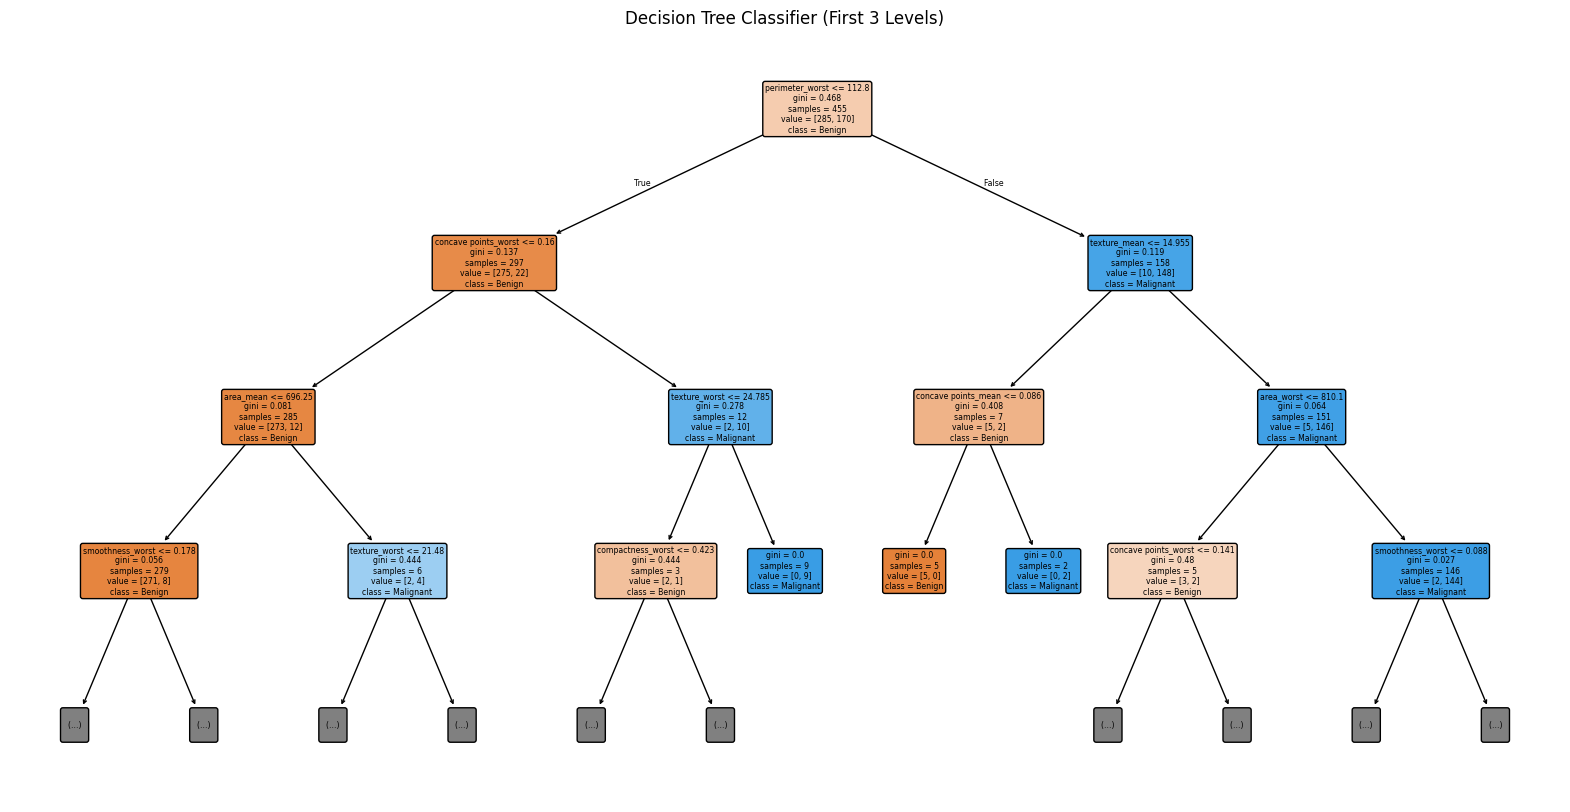

In [209]:
# Decision tree, dataset training, the evaluation metrics and visualizing the tree for output easier interpretation

dt_model = DecisionTreeClassifier( criterion='gini', max_depth = None, random_state = 42 )
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[ : , 1]

dt_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_dt),
    'AUC': roc_auc_score(y_test, y_prob_dt),
    'Precision': precision_score(y_test, y_pred_dt, pos_label = 1),
    'Recall': recall_score(y_test, y_pred_dt, pos_label = 1),
    'F1 Score': f1_score(y_test, y_pred_dt, pos_label = 1),
    'MCC': matthews_corrcoef(y_test, y_pred_dt)
}

print("Decision Tree Results:\n")
for metric, value in dt_metrics.items():
    print(f"{metric}: {value}")

# Plotting the tree
plt.figure(figsize = ( 20, 10 ))
plot_tree( dt_model, feature_names = X_train.columns, class_names = ['Benign', 'Malignant'], filled = True, rounded = True, max_depth = 3 )
plt.title("Decision Tree Classifier (First 3 Levels)")
plt.show()


In [210]:
# KNN model initialization, training and evaluating the training with evaluation metrics
knn_model = KNeighborsClassifier( n_neighbors = 5, metric = 'minkowski', p = 2 )
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)
y_prob_knn = knn_model.predict_proba(X_test_scaled)[ : , 1]

knn_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_knn),
    'AUC': roc_auc_score(y_test, y_prob_knn),
    'Precision': precision_score(y_test, y_pred_knn, pos_label = 1),
    'Recall': recall_score(y_test, y_pred_knn, pos_label = 1),
    'F1 Score': f1_score(y_test, y_pred_knn, pos_label = 1),
    'MCC': matthews_corrcoef(y_test, y_pred_knn)
}

print("KNN Results:\n")

for metric, value in knn_metrics.items():
    print(f"{metric}: {value}")

KNN Results:

Accuracy: 0.956140350877193
AUC: 0.982308201058201
Precision: 0.9743589743589743
Recall: 0.9047619047619048
F1 Score: 0.9382716049382716
MCC: 0.9058238738943076


In [211]:
# Gaussian Naive Bayes Classifier model training and testing with evaluation metrics
nb_model = GaussianNB()

nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)
y_prob_nb = nb_model.predict_proba(X_test)[ : , 1]

nb_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_nb),
    'AUC': roc_auc_score(y_test, y_prob_nb),
    'Precision': precision_score(y_test, y_pred_nb, pos_label = 1),
    'Recall': recall_score(y_test, y_pred_nb, pos_label = 1),
    'F1 Score': f1_score(y_test, y_pred_nb, pos_label = 1),
    'MCC': matthews_corrcoef(y_test, y_pred_nb)
}

print("Gaussian Naive Bayes Results:\n")
for metric, value in nb_metrics.items():
    print(f"{metric}: {value}")


Gaussian Naive Bayes Results:

Accuracy: 0.9385964912280702
AUC: 0.9933862433862434
Precision: 1.0
Recall: 0.8333333333333334
F1 Score: 0.9090909090909091
MCC: 0.8714893406611902


In [212]:
# Support Vector Machines model training and evaluation metrics testing

svm_model = SVC( kernel = 'rbf', C = 1.0, gamma = 'scale', probability = True, random_state = 42 )
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[ : , 1]

svm_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_svm),
    'AUC': roc_auc_score(y_test, y_prob_svm),
    'Precision': precision_score(y_test, y_pred_svm, pos_label = 1),
    'Recall': recall_score(y_test, y_pred_svm, pos_label = 1),
    'F1 Score': f1_score(y_test, y_pred_svm, pos_label = 1),
    'MCC': matthews_corrcoef(y_test, y_pred_svm)
}

print("Support Vector Machine Results:\n")
for metric, value in svm_metrics.items():
    print(f"{metric}: {value:}")


Support Vector Machine Results:

Accuracy: 0.9736842105263158
AUC: 0.9947089947089947
Precision: 1.0
Recall: 0.9285714285714286
F1 Score: 0.9629629629629629
MCC: 0.9441549509633318


<h3>Output Interpretation</h3>

In [214]:
# Creating a comparison table to draft the results and use that for easier comparison
comparison_df = pd.DataFrame({
    'Logistic Regression': lr_metrics,
    'Decision Tree': dt_metrics,
    'KNN': knn_metrics,
    'Gaussian Naive Bayes': nb_metrics,
    'SVM': svm_metrics
})

comparison_df = comparison_df.T

# Assign weights to all six evaluation metrics so that most required metric is given a higher weightage. Assuming equal weightage for the time being
weights = {
    'Accuracy': 1/6,
    'AUC': 1/6,
    'Precision': 1/6,
    'Recall': 1/6,
    'F1 Score': 1/6,
    'MCC': 1/6
}

comparison_df['Weighted Score'] = sum( comparison_df[metric] * weight for metric, weight in weights.items() )

# Generating a scoring table to check the best model based on overall score
ranked_models = comparison_df.sort_values( by = 'Weighted Score', ascending = False )

display(ranked_models.round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC,Weighted Score
SVM,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442,0.9673
Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245,0.9567
KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058,0.9436
Gaussian Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715,0.9243
Decision Tree,0.9298,0.9246,0.9048,0.9048,0.9048,0.8492,0.9030


In [215]:
os.makedirs('models', exist_ok = True)

<h3>Saving All Models And Required Artifacts As Files</h3>

In [ ]:
# Saving trained models as individual joblib files
joblib.dump(lr_model, 'model/logistic_regression.pkl')
joblib.dump(dt_model, 'model/decision_tree.pkl')
joblib.dump(knn_model, 'model/knn.pkl')
joblib.dump(nb_model, 'model/gaussian_nb.pkl')
joblib.dump(svm_model, 'model/svm.pkl')

print("All five models saved successfully!")

All five models saved successfully!


In [ ]:
# Saving pre-processing scaler logic
joblib.dump(scaler, 'model/scaler.pkl')
joblib.dump(list(X_train.columns), 'model/feature_names.pkl')


['models/feature_names.pkl']

In [238]:
# Saving the test dataset
test_data = X_test.copy()
test_data['diagnosis'] = y_test
test_data.to_csv('test_dataset.csv', index = False)

print("Test dataset saved!")

Test dataset saved!
